In [2]:
import sys
import pandas as pd
import torch
import torch.nn as nn

# Pour rendre plus large l'affichage Pandas
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# Chemin vers les scripts
sys.path.append("../src/")
sys.path.append("../models/")

from src.preprocess import load_and_filter_data, train_val_test_split, prepare_datasets, numpy_to_torch
from src.train import train_model
from src.evaluate import predict, compute_metrics
from src.visualization import plot_loss, plot_predictions_compare, plot_prediction_lstm, barplot_metrics

from models.lstm_model import LSTMModel
from models.gru_model import GRUModel
from models.attention_model import AttentionModel

device = torch.device("cuda")
print("Device utilisé:", device)

Device utilisé: cuda


Aperçu df :
                 close
date                  
2015-01-01  314.248993
2015-01-02  315.032013
2015-01-03  281.082001
2015-01-04  264.195007
2015-01-05  274.473999
Shape : (3732, 1)


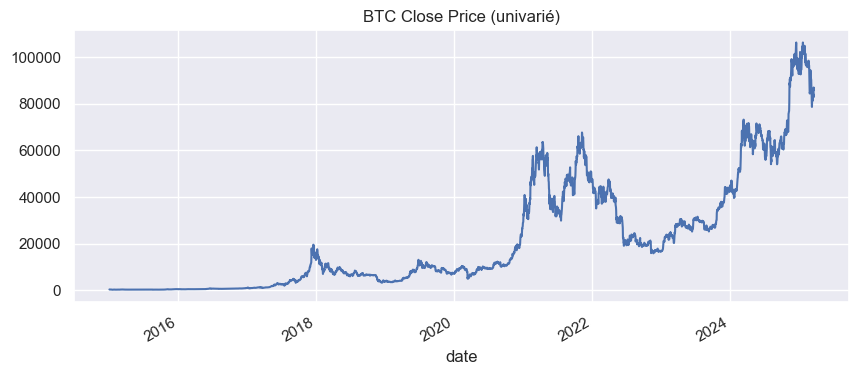

In [3]:
csv_path = "data\BTC.csv"
df = load_and_filter_data(csv_path)

print("Aperçu df :")
print(df.head())
print("Shape :", df.shape)

df['close'].plot(title="BTC Close Price (univarié)", figsize=(10,4))
plt.show()


In [4]:
# Split
df_train, df_val, df_test = train_val_test_split(df, 0.8, 0.1)
print("Train set size:", len(df_train))
print("Val set size:  ", len(df_val))
print("Test set size: ", len(df_test))

Train set size: 2985
Val set size:   373
Test set size:  374


In [5]:
window_size = 30
horizons = [1,3,7]

datasets = {}
for h in horizons:
    X_train, y_train, X_val, y_val, X_test, y_test, scaler = prepare_datasets(
        df_train, df_val, df_test, 
        window_size=window_size, horizon=h
    )
    datasets[h] = {
        'X_train': X_train,
        'y_train': y_train,
        'X_val':   X_val,
        'y_val':   y_val,
        'X_test':  X_test,
        'y_test':  y_test,
        'scaler':  scaler
    }

In [6]:
import json
import torch
import torch.nn as nn

lstm_config_path = r"LSTM\config.json"
lstm_weights_path = r"LSTM\pytorch_model.bin"

with open(lstm_config_path, 'r') as f:
    config_lstm = json.load(f)

print("Config LSTM pré-entraîné:", config_lstm)

pretrained_lstm = LSTMModel(
    input_dim=config_lstm["input_dim"],   # ex: 1
    hidden_dim=config_lstm["hidden_dim"],
    num_layers=config_lstm["num_layers"],
    output_dim=config_lstm["output_dim"]
)

# Charger le checkpoint (sauvegardé avec input_dim=1)
state_dict = torch.load(lstm_weights_path, map_location='cpu')
pretrained_lstm.load_state_dict(state_dict)
pretrained_lstm.eval()
print("LSTM pré-entraîné chargé avec succès.")

Config LSTM pré-entraîné: {'input_dim': 1, 'hidden_dim': 64, 'num_layers': 5, 'output_dim': 1, 'num_epochs': 500}
LSTM pré-entraîné chargé avec succès.



=== Entraînement GRU - horizon=1 ===
[Epoch 1/100] train_loss=0.015045, val_loss=0.001585
[Epoch 2/100] train_loss=0.000715, val_loss=0.001281
[Epoch 3/100] train_loss=0.000517, val_loss=0.000581
[Epoch 4/100] train_loss=0.000456, val_loss=0.000466
[Epoch 5/100] train_loss=0.000424, val_loss=0.000411
[Epoch 6/100] train_loss=0.000459, val_loss=0.000785
[Epoch 7/100] train_loss=0.000317, val_loss=0.000380
[Epoch 8/100] train_loss=0.000352, val_loss=0.000277
[Epoch 9/100] train_loss=0.000282, val_loss=0.000966
[Epoch 10/100] train_loss=0.000250, val_loss=0.000326
[Epoch 11/100] train_loss=0.000265, val_loss=0.000296
[Epoch 12/100] train_loss=0.000243, val_loss=0.000644
[Epoch 13/100] train_loss=0.000289, val_loss=0.000351
[Epoch 14/100] train_loss=0.000248, val_loss=0.000248
[Epoch 15/100] train_loss=0.000240, val_loss=0.000242
[Epoch 16/100] train_loss=0.000209, val_loss=0.001067
[Epoch 17/100] train_loss=0.000280, val_loss=0.000633
[Epoch 18/100] train_loss=0.000225, val_loss=0.000474

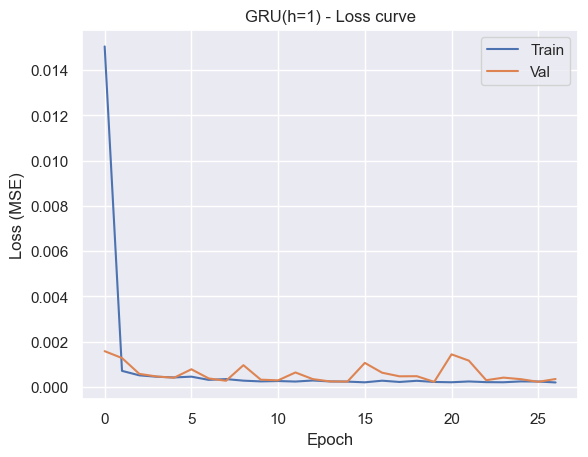


=== Entraînement Attention - horizon=1 ===
[Epoch 1/100] train_loss=0.030780, val_loss=0.008135
[Epoch 2/100] train_loss=0.003890, val_loss=0.008542
[Epoch 3/100] train_loss=0.003216, val_loss=0.005198
[Epoch 4/100] train_loss=0.003058, val_loss=0.006666
[Epoch 5/100] train_loss=0.002742, val_loss=0.006168
[Epoch 6/100] train_loss=0.002614, val_loss=0.004174
[Epoch 7/100] train_loss=0.002259, val_loss=0.004404
[Epoch 8/100] train_loss=0.002393, val_loss=0.002780
[Epoch 9/100] train_loss=0.002400, val_loss=0.003652
[Epoch 10/100] train_loss=0.001905, val_loss=0.004522
[Epoch 11/100] train_loss=0.001822, val_loss=0.004563
[Epoch 12/100] train_loss=0.001821, val_loss=0.002635
[Epoch 13/100] train_loss=0.001257, val_loss=0.001607
[Epoch 14/100] train_loss=0.000993, val_loss=0.001050
[Epoch 15/100] train_loss=0.001101, val_loss=0.002857
[Epoch 16/100] train_loss=0.000949, val_loss=0.001033
[Epoch 17/100] train_loss=0.000665, val_loss=0.000959
[Epoch 18/100] train_loss=0.000748, val_loss=0.

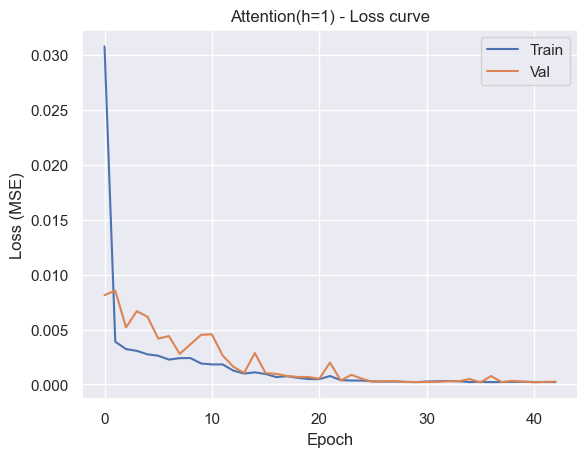

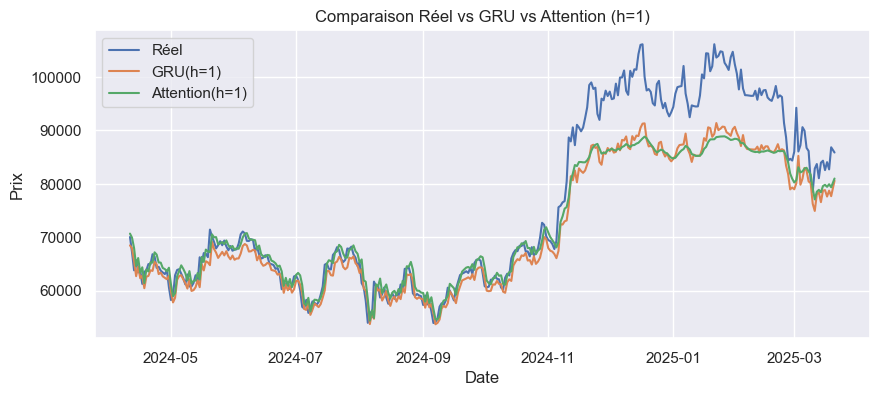


=== Entraînement GRU - horizon=3 ===
[Epoch 1/100] train_loss=0.021110, val_loss=0.003353
[Epoch 2/100] train_loss=0.001042, val_loss=0.001893
[Epoch 3/100] train_loss=0.001014, val_loss=0.001177
[Epoch 4/100] train_loss=0.000788, val_loss=0.000990
[Epoch 5/100] train_loss=0.000781, val_loss=0.002575
[Epoch 6/100] train_loss=0.000681, val_loss=0.000989
[Epoch 7/100] train_loss=0.000779, val_loss=0.000995
[Epoch 8/100] train_loss=0.000568, val_loss=0.001599
[Epoch 9/100] train_loss=0.000608, val_loss=0.001016
[Epoch 10/100] train_loss=0.000594, val_loss=0.001238
[Epoch 11/100] train_loss=0.000550, val_loss=0.000852
[Epoch 12/100] train_loss=0.000534, val_loss=0.002064
[Epoch 13/100] train_loss=0.000658, val_loss=0.000704
[Epoch 14/100] train_loss=0.000544, val_loss=0.001011
[Epoch 15/100] train_loss=0.000652, val_loss=0.001305
[Epoch 16/100] train_loss=0.000515, val_loss=0.001214
[Epoch 17/100] train_loss=0.000568, val_loss=0.000951
[Epoch 18/100] train_loss=0.000573, val_loss=0.001161

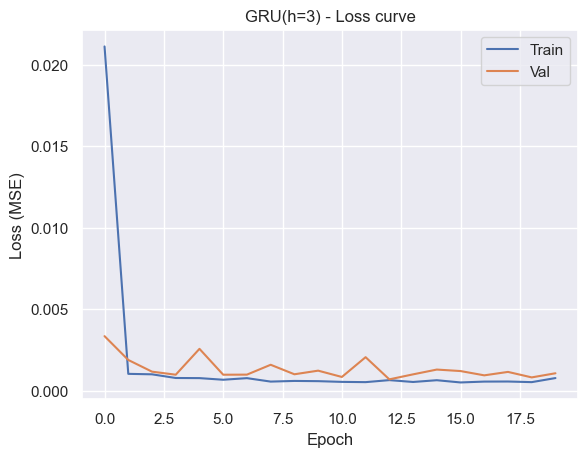


=== Entraînement Attention - horizon=3 ===
[Epoch 1/100] train_loss=0.024109, val_loss=0.007937
[Epoch 2/100] train_loss=0.003644, val_loss=0.012327
[Epoch 3/100] train_loss=0.003452, val_loss=0.013610
[Epoch 4/100] train_loss=0.003669, val_loss=0.006580
[Epoch 5/100] train_loss=0.003096, val_loss=0.006091
[Epoch 6/100] train_loss=0.002834, val_loss=0.004238
[Epoch 7/100] train_loss=0.002781, val_loss=0.004171
[Epoch 8/100] train_loss=0.002705, val_loss=0.004732
[Epoch 9/100] train_loss=0.002379, val_loss=0.004128
[Epoch 10/100] train_loss=0.002248, val_loss=0.003779
[Epoch 11/100] train_loss=0.001514, val_loss=0.004206
[Epoch 12/100] train_loss=0.001726, val_loss=0.002428
[Epoch 13/100] train_loss=0.001590, val_loss=0.002256
[Epoch 14/100] train_loss=0.001167, val_loss=0.001835
[Epoch 15/100] train_loss=0.001202, val_loss=0.001892
[Epoch 16/100] train_loss=0.000999, val_loss=0.001975
[Epoch 17/100] train_loss=0.001058, val_loss=0.002071
[Epoch 18/100] train_loss=0.001062, val_loss=0.

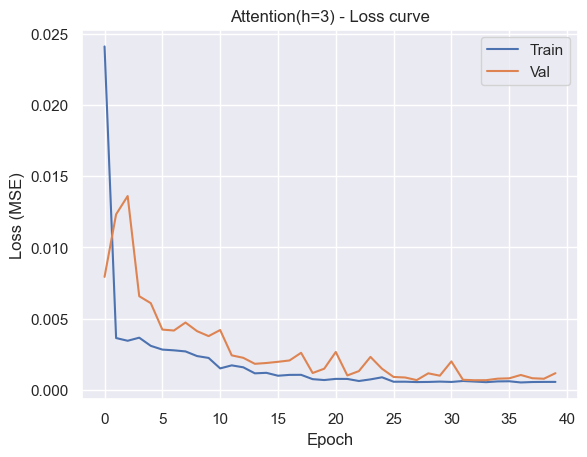

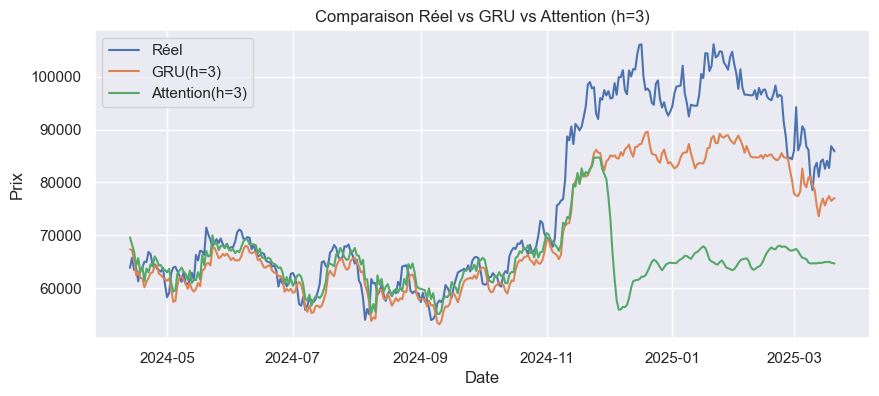


=== Entraînement GRU - horizon=7 ===
[Epoch 1/100] train_loss=0.011626, val_loss=0.003339
[Epoch 2/100] train_loss=0.001761, val_loss=0.002788
[Epoch 3/100] train_loss=0.001804, val_loss=0.002408
[Epoch 4/100] train_loss=0.001741, val_loss=0.002371
[Epoch 5/100] train_loss=0.001330, val_loss=0.002624
[Epoch 6/100] train_loss=0.001311, val_loss=0.003212
[Epoch 7/100] train_loss=0.001445, val_loss=0.001740
[Epoch 8/100] train_loss=0.001253, val_loss=0.001848
[Epoch 9/100] train_loss=0.001432, val_loss=0.001928
[Epoch 10/100] train_loss=0.001359, val_loss=0.002747
[Epoch 11/100] train_loss=0.001398, val_loss=0.003727
[Epoch 12/100] train_loss=0.001304, val_loss=0.001974
[Epoch 13/100] train_loss=0.001303, val_loss=0.001695
[Epoch 14/100] train_loss=0.001219, val_loss=0.002108
[Epoch 15/100] train_loss=0.001310, val_loss=0.002324
[Epoch 16/100] train_loss=0.001195, val_loss=0.002210
[Epoch 17/100] train_loss=0.001100, val_loss=0.001817
[Epoch 18/100] train_loss=0.001151, val_loss=0.001777

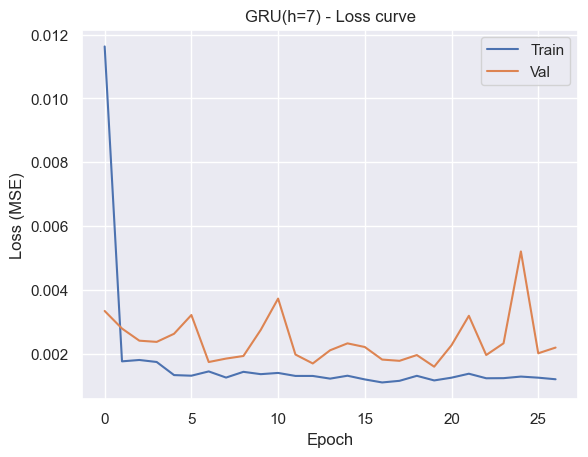


=== Entraînement Attention - horizon=7 ===
[Epoch 1/100] train_loss=0.035900, val_loss=0.013359
[Epoch 2/100] train_loss=0.004891, val_loss=0.008422
[Epoch 3/100] train_loss=0.003995, val_loss=0.011150
[Epoch 4/100] train_loss=0.003981, val_loss=0.009655
[Epoch 5/100] train_loss=0.003706, val_loss=0.005753
[Epoch 6/100] train_loss=0.003581, val_loss=0.005234
[Epoch 7/100] train_loss=0.003449, val_loss=0.006391
[Epoch 8/100] train_loss=0.003556, val_loss=0.005099
[Epoch 9/100] train_loss=0.003262, val_loss=0.005514
[Epoch 10/100] train_loss=0.002971, val_loss=0.006197
[Epoch 11/100] train_loss=0.002845, val_loss=0.004966
[Epoch 12/100] train_loss=0.002975, val_loss=0.003607
[Epoch 13/100] train_loss=0.002830, val_loss=0.012050
[Epoch 14/100] train_loss=0.003070, val_loss=0.006878
[Epoch 15/100] train_loss=0.002521, val_loss=0.004456
[Epoch 16/100] train_loss=0.002423, val_loss=0.006423
[Epoch 17/100] train_loss=0.002445, val_loss=0.004583
[Epoch 18/100] train_loss=0.002188, val_loss=0.

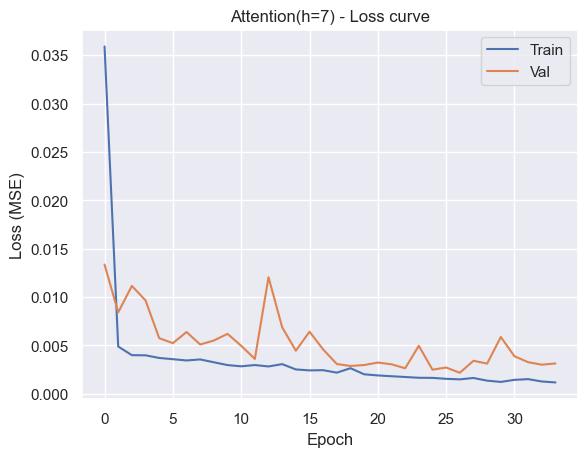

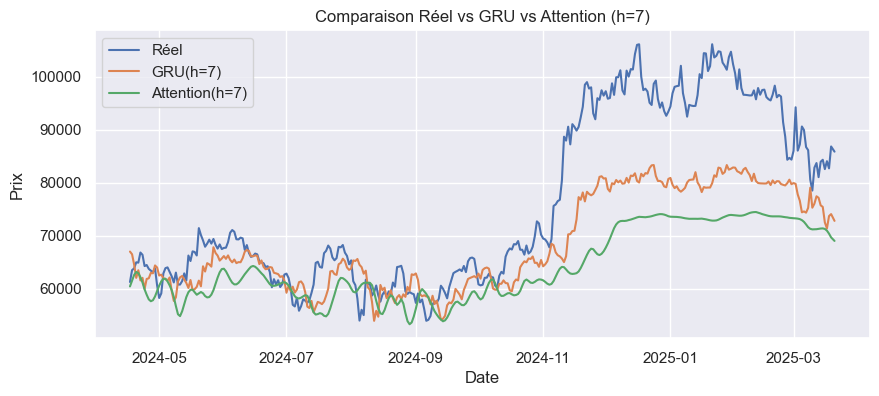

In [10]:
results = []


for horizon in horizons:
    data_h = datasets[horizon]
    X_train, y_train = data_h['X_train'], data_h['y_train']
    X_val,   y_val   = data_h['X_val'],   data_h['y_val']
    X_test,  y_test  = data_h['X_test'],  data_h['y_test']
    scaler = data_h['scaler']
    
    # Convertir en tenseurs
    X_train_t, y_train_t = numpy_to_torch(X_train, y_train)
    X_val_t,   y_val_t   = numpy_to_torch(X_val, y_val)
    X_test_t,  y_test_t  = numpy_to_torch(X_test, y_test)
    
    train_ds = torch.utils.data.TensorDataset(X_train_t, y_train_t)
    val_ds   = torch.utils.data.TensorDataset(X_val_t,   y_val_t)
    test_ds  = torch.utils.data.TensorDataset(X_test_t,  y_test_t)
    
    batch_size = 32
    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = torch.utils.data.DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
    test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=batch_size, shuffle=False)
    
    # On reprend la même config (input_dim=1, hidden_dim=64, etc.)
    input_dim  = config_lstm["input_dim"]   # 1
    hidden_dim = config_lstm["hidden_dim"]  # 64
    num_layers = config_lstm["num_layers"]  # 5
    output_dim = config_lstm["output_dim"]  # 1
    
    # === GRU ===
    print(f"\n=== Entraînement GRU - horizon={horizon} ===")
    gru_model = GRUModel(input_dim, hidden_dim, num_layers, output_dim)
    train_cfg_gru = {"lr":1e-3, "epochs":100, "patience":7}
    best_gru, gru_history = train_model(gru_model, train_loader, val_loader, train_cfg_gru)
    plot_loss(gru_history, title=f"GRU(h={horizon}) - Loss curve")
    
    # === Attention ===
    print(f"\n=== Entraînement Attention - horizon={horizon} ===")
    att_model = AttentionModel(input_dim, hidden_dim, num_layers, output_dim)
    train_cfg_att = {"lr":1e-3, "epochs":100, "patience":7}
    best_att, att_history = train_model(att_model, train_loader, val_loader, train_cfg_att)
    plot_loss(att_history, title=f"Attention(h={horizon}) - Loss curve")
    
    # Evaluation sur test
    gru_preds, gru_trues = predict(best_gru, test_loader)
    att_preds, att_trues = predict(best_att, test_loader)
    
    # Inverse transform sur la col 'close' => On a un seul feature
    inv_gru_preds = scaler.inverse_transform(gru_preds)
    inv_gru_trues = scaler.inverse_transform(gru_trues)
    inv_att_preds = scaler.inverse_transform(att_preds)
    inv_att_trues = scaler.inverse_transform(att_trues)
    
    gru_metrics = compute_metrics(inv_gru_preds, inv_gru_trues)
    att_metrics = compute_metrics(inv_att_preds, inv_att_trues)
    
    results.append({"Model":"GRU",        "Horizon":horizon, **gru_metrics})
    results.append({"Model":"Attention", "Horizon":horizon, **att_metrics})
    
    # Graph
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(inv_gru_preds):
        plot_predictions_compare(test_dates, inv_gru_trues.flatten(), inv_gru_preds.flatten(), inv_att_preds.flatten(), horizon)

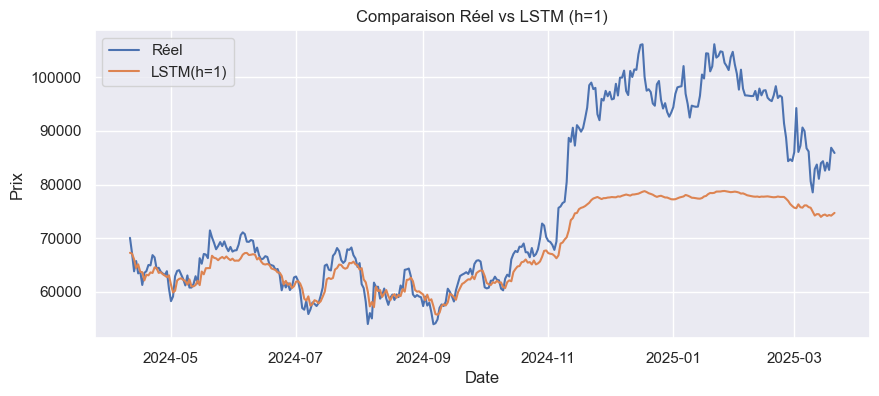

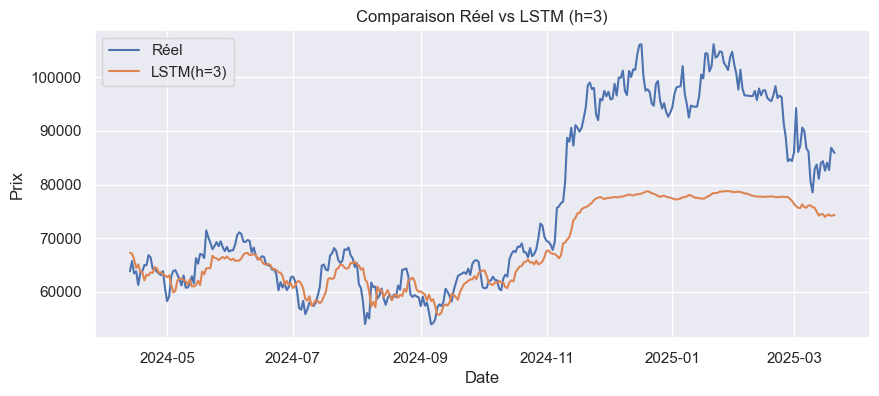

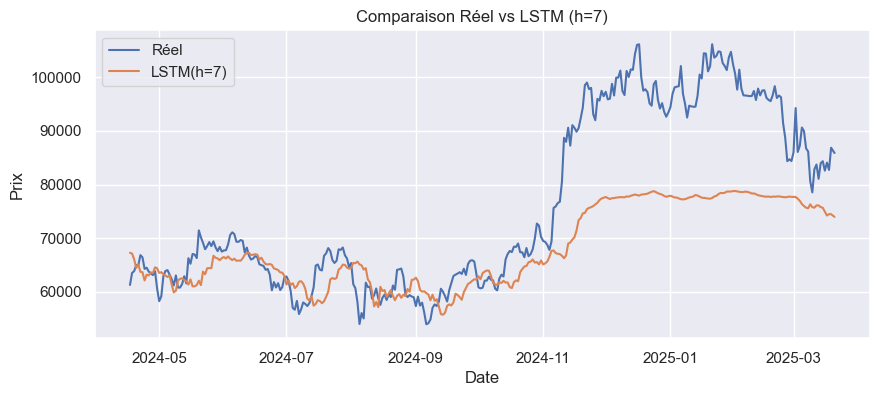

In [12]:
for horizon in horizons:
    data_h = datasets[horizon]
    X_test, y_test = data_h['X_test'], data_h['y_test']
    scaler = data_h['scaler']
    
    X_test_t, y_test_t = numpy_to_torch(X_test, y_test)
    test_ds = torch.utils.data.TensorDataset(X_test_t, y_test_t)
    test_loader = torch.utils.data.DataLoader(test_ds, batch_size=32, shuffle=False)
    
    lstm_preds, lstm_trues = predict(pretrained_lstm, test_loader)
    
    # On inverse transform
    def inverse_transform(preds, trues):
        nb_feats = 5
        arr_pred = np.zeros((len(preds), nb_feats))
        arr_true = np.zeros((len(trues), nb_feats))
        close_idx = list(df_train.columns).index('close')
        arr_pred[:, close_idx] = preds.ravel()
        arr_true[:, close_idx] = trues.ravel()
        
        inv_pred = scaler.inverse_transform(arr_pred)[:, close_idx]
        inv_true = scaler.inverse_transform(arr_true)[:, close_idx]
        return inv_pred, inv_true
    
    lstm_pred_inv, lstm_true_inv = inverse_transform(lstm_preds, lstm_trues)
    lstm_metrics = compute_metrics(lstm_pred_inv.reshape(-1,1), lstm_true_inv.reshape(-1,1))
    
    results.append({"Model":"LSTM_pretrained", "Horizon":horizon, **lstm_metrics})
    
    # Plot
    test_dates = df_test.index[-len(test_ds):]
    if len(test_dates) == len(lstm_pred_inv):
        plot_prediction_lstm(test_dates, lstm_true_inv, lstm_pred_inv, horizon)



=== Résultats finaux ===
             Model  Horizon           MAE          RMSE       MAPE        R2
0              GRU        1   4739.243164   6564.452452   5.419070  0.833770
1        Attention        1   4577.134766   6692.364007   5.164821  0.827229
2              GRU        3   6088.290039   7978.382292   7.171141  0.755587
3        Attention        3  11990.716797  18441.460246  13.138130 -0.305826
4              GRU        7   8317.857422  11032.669305   9.679302  0.535255
5        Attention        7  12102.265625  15758.643089  14.048198  0.051819
6  LSTM_pretrained        1   8008.228237  11715.077978   8.861797  0.470578
7  LSTM_pretrained        3   8439.195729  11917.083952   9.515506  0.454701
8  LSTM_pretrained        7   9039.624767  12294.676638  10.377987  0.422852


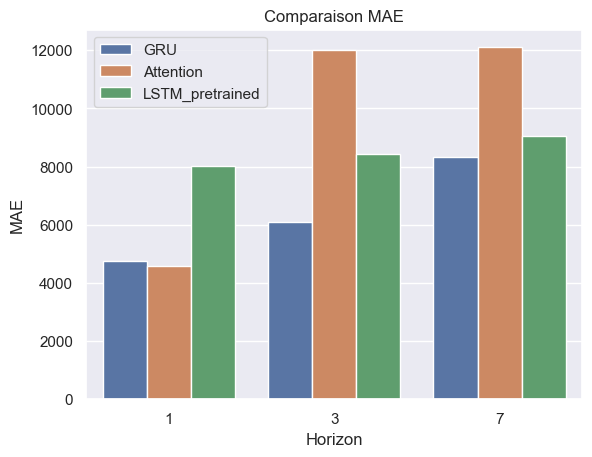

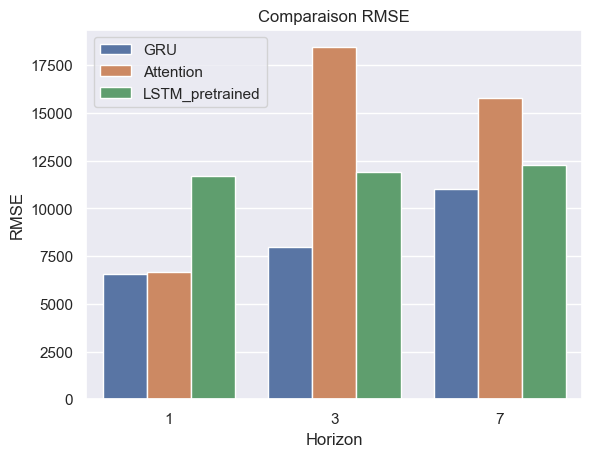

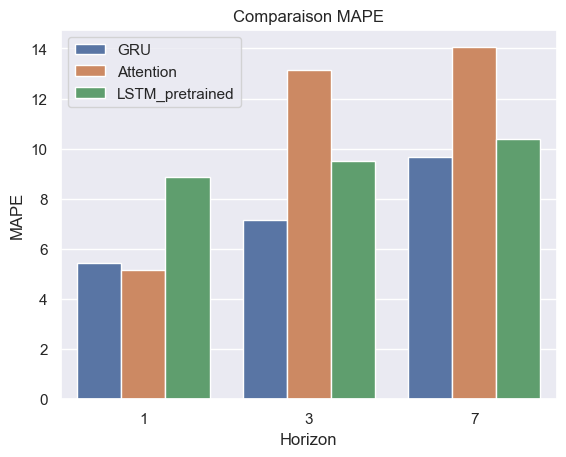

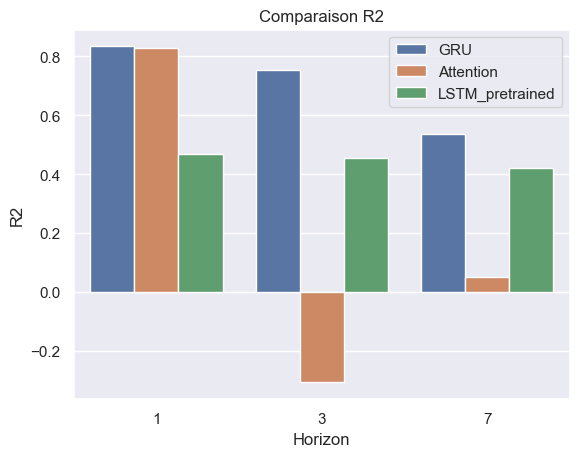

In [13]:
df_results = pd.DataFrame(results)
print("\n=== Résultats finaux ===")
print(df_results)

barplot_metrics(df_results)